# European cars: simple and nested logit (OLS and IV)

Choose **Run All**. Keep the data at `data/cars.csv` beside this notebook.

1. Estimate demand with the same two count instruments in both IV models.
2. Calculate elasticities and diversion ratios.
3. Simulate VW-Fiat in all 150 markets, compare welfare and plot countries.

The last two blocks reproduce the report's robustness and theory results.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import pyhdfe, pyblp
import matplotlib.pyplot as plt
from linearmodels.iv import IV2SLS
from scipy.special import logsumexp
from scipy.optimize import brentq
from IPython.display import display
import scienceplots 
plt.style.use(["science", "grid"])
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "figure.titlesize": 15,
})
pyblp.options.verbose = False
pd.set_option('display.precision',5)

OUT = Path('output'); OUT.mkdir(exist_ok=True)

In [2]:
cars = pd.read_csv('data/cars.csv').sort_values(['ma','ye','co']).reset_index(drop=True)
cars['market_ids'] = cars.ma.astype(str)+'_'+cars.ye.astype(str)
cars['firm_ids'], cars['nesting_ids'], cars['clustering_ids'] = cars.frm, cars.cla, cars.co
cars['prices'] = cars.princ/(1+cars.tax)
cars['weight'], cars['power'] = cars.we/1000, cars.hp/100
cars['neg_log_price'] = -np.log(cars.princ)
controls = ['weight','power','li','home']
countries = {1:'Belgium',2:'France',3:'Germany',4:'Italy',5:'UK'}
assert len(cars)==6000 and cars.groupby('market_ids').size().eq(40).all()

# Two COUNT instruments: other own-firm and rival cars in the same class.
# A third count (rival cars in other classes) is used only for robustness.
Z = np.zeros((len(cars),2))
other_class_count = np.zeros(len(cars))
for _, g in cars.groupby('market_ids',sort=False):
    rival = g.frm.to_numpy()[:,None] != g.frm.to_numpy()[None,:]
    same_class = g.cla.to_numpy()[:,None] == g.cla.to_numpy()[None,:]
    Z[g.index,0] = (rival & same_class).sum(1)
    Z[g.index,1] = (~rival & same_class).sum(1)-1  # exclude the car itself
    other_class_count[g.index] = (rival & ~same_class).sum(1)
Z /= Z.std(axis=0,ddof=0)

def data_for(h):
    d = cars.copy()
    d['shares'] = d.qu/(d['pop']/h)
    outside = 1-d.groupby('market_ids').shares.transform('sum')
    assert outside.between(0,1,inclusive='neither').all()
    d['delta'] = np.log(d.shares/outside)
    d['log_within'] = np.log(d.shares/d.groupby(['market_ids','cla']).shares.transform('sum'))
    return d

## 1. Demand estimation
log(s_j/s_0) = -alpha*log(princ) + x*beta + country FE + brand FE
                + rho*log(s_j/s_class) + error.
Simple logit sets rho=0. Nested logit estimates rho with nests on class.
Nested IV instruments BOTH price and within-class share with the two IVs.
Exclusion is an assumption about product positioning/assortment; it is
not established by first-stage relevance. SEs cluster by car model.

In [3]:
X1 = pyblp.Formulation(
    '0 + I(log(prices*(1+tax))) + weight + power + li + home',
    absorb='C(ma) + C(brd)'
)
def fit_models(d,instruments=Z,effects=('ma','brd')):
    a = pyhdfe.create(d[list(effects)].to_numpy(),drop_singletons=False)
    cols = ['delta','neg_log_price','log_within']+controls
    r = pd.DataFrame(a.residualize(d[cols].to_numpy()),columns=cols)
    z = a.residualize(instruments)
    fits = {}
    for family,endog in [('Logit',['neg_log_price']),('Nested',['neg_log_price','log_within'])]:
        fits[family+' OLS'] = sm.OLS(r.delta,r[endog+controls]).fit(
            cov_type='cluster',cov_kwds={'groups':d.co,'use_correction':False})
        fits[family+' IV'] = IV2SLS(r.delta,r[controls],r[endog],z).fit(
            cov_type='clustered',clusters=d.co,debiased=False)
    return fits

def pricing_model(d,fit):
    b = fit.params.reindex(['neg_log_price']+controls).to_numpy()[:,None]
    b[0] *= -1  # PyBLP uses +log(price), so its coefficient is -alpha.
    rho = fit.params.get('log_within',0.)
    return pyblp.Problem(X1,d).solve(beta=b,beta_bounds=(b,b),rho=rho,
        rho_bounds=(rho,rho),method='1s',optimization=pyblp.Optimization('return'))

data = data_for(2.5)
fits = fit_models(data)
coef, stages, models = [], [], {}
for name,fit in fits.items():
    se = fit.bse if name.endswith('OLS') else fit.std_errors
    for term in fit.params.index:
        coef.append({'Model':name,'Parameter':term,'Estimate':fit.params[term],'SE':se[term]})
    assert fit.params.neg_log_price>1 and 0<=fit.params.get('log_within',0)<1
    models[name] = pricing_model(data,fit)
    if name.endswith('IV'):
        fs = fit.first_stage.diagnostics.copy()
        fs['Model'], fs['Clustered Wald / q'] = name, fs['f.stat']/Z.shape[1]
        stages.append(fs)
coefficients = pd.DataFrame(coef)
order = ['Logit OLS','Logit IV','Nested OLS','Nested IV']
table = coefficients.assign(Value=coefficients.apply(
    lambda r:f'{r.Estimate:.3f} ({r.SE:.3f})',axis=1)).pivot(
    index='Parameter',columns='Model',values='Value')
display(table.reindex(['neg_log_price','log_within']+controls)[order])
first_stages = pd.concat(stages)
display(first_stages[['Model','Clustered Wald / q']])
coefficients.to_csv(OUT/'coefficients.csv',index=False)
first_stages.to_csv(OUT/'first_stages.csv')

Model,Logit OLS,Logit IV,Nested OLS,Nested IV
Parameter,,,,
neg_log_price,1.145 (0.139),2.393 (0.628),1.163 (0.104),4.114 (1.553)
log_within,NaN,NaN,0.658 (0.026),0.168 (0.140)
weight,1.300 (0.254),1.863 (0.402),0.175 (0.162),2.351 (0.629)
power,-0.322 (0.250),0.492 (0.498),-0.016 (0.185),1.689 (1.102)
li,-0.101 (0.019),-0.031 (0.039),-0.072 (0.013),0.072 (0.090)
home,1.238 (0.050),1.253 (0.048),0.544 (0.063),1.096 (0.148)


,Model,Clustered Wald / q
neg_log_price,Logit IV,12.17588
neg_log_price,Nested IV,12.17588
log_within,Nested IV,136.38998


## 2. Elasticities and diversion
Elasticity E[j,k] = (ds_j/dp_k)*p_k/s_j. Diversion from j to k is
-(ds_k/dp_j)/(ds_j/dp_j). Simple-logit diversion is s_k/(1-s_j),
so OLS and IV have identical diversion at observed shares. Nesting
increases substitution within a class; IV changes both alpha and rho.

In [4]:
substitution, diversion = [], []
for name,r in models.items():
    E, jacobians = r.compute_elasticities(), r.compute_demand_jacobians()
    own, same_cross, partner = [], [], []
    for market,g in data.groupby('market_ids',sort=False):
        e, J = E[g.index], jacobians[g.index]
        # Rows are the source car (price raised), columns the destination.
        dv = -J.T/np.diag(J)[:,None]
        np.fill_diagonal(dv,0.)
        f, cl = g.frm.to_numpy(), g.cla.to_numpy()
        merging = np.isin(f,[4,26])
        target = merging[:,None]&merging[None,:]&(f[:,None]!=f[None,:])
        same = cl[:,None]==cl[None,:]; off = ~np.eye(40,dtype=bool)
        own.extend(np.diag(e))
        same_cross.extend(e[same&off])
        value = 100*np.average((dv*target).sum(1)[merging],weights=g.qu[merging])
        partner.append(value)
        diversion.append({'Model':name,'market':market,'country':countries[g.ma.iloc[0]],'Partner diversion (%)':value})
    substitution.append({'Model':name,'Median own elasticity':np.median(own),
        'Mean within-class cross elasticity':np.mean(same_cross),'Partner diversion (%)':np.mean(partner)})
substitution = pd.DataFrame(substitution).set_index('Model')
display(substitution);substitution.to_csv(OUT/'substitution.csv')
pd.DataFrame(diversion).to_csv(OUT/'diversion.csv',index=False)

,Median own elasticity,Mean within-class cross elasticity,Partner diversion (%)
Model,,,
Logit OLS,-1.14406,0.00218,0.56381
Logit IV,-2.39015,0.00456,0.56381
Nested OLS,-3.23071,0.20831,5.66087
Nested IV,-4.87730,0.08445,1.77378


## 3. Merger, welfare and efficiencies in every market
Fiat (4) merges into VW (26); all firms reprice. Costs, VAT and qualities
remain fixed. Marginal costs are inferred separately under each model.
Welfare is expected logsum utility. Its uniform-price equivalent is the
increase in all baseline prices giving the same utility loss. With log
prices, dividing the logsum by alpha does NOT give monetary CS.

Solved all markets: Logit OLS
Solved all markets: Logit IV
Solved all markets: Nested OLS
Solved all markets: Nested IV


,Price change (%),Median own elasticity,Mean within-class cross elasticity,Partner diversion (%),Welfare equivalent (%),Every-market welfare neutrality (%)
Model,,,,,,
Logit OLS,4.3092,-1.1441,0.0022,0.5638,1.5231,27.8705
Logit IV,0.4489,-2.3901,0.0046,0.5638,0.1722,1.9630
Nested OLS,3.3053,-3.2307,0.2083,5.6609,1.2903,21.7332
Nested IV,0.5052,-4.8773,0.0844,1.7738,0.1925,1.8954


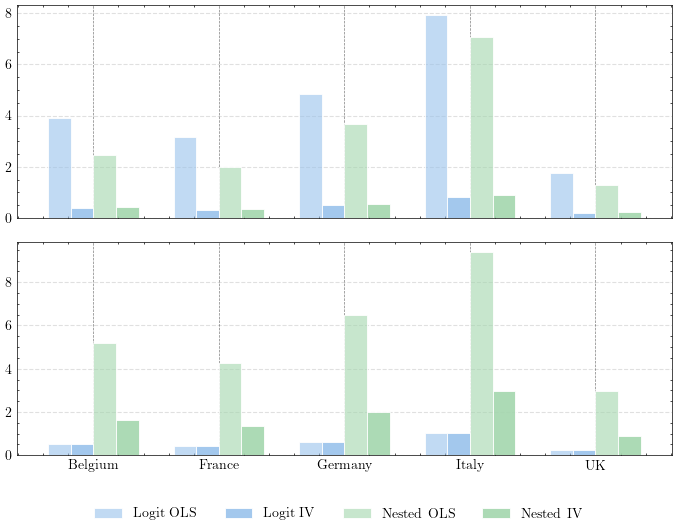

In [ ]:
iteration = pyblp.Iteration('squarem',{'atol':1e-12,'max_evaluations':3000})
def counterfactual(d,fitted,efficiencies=False):
    rows,products,savings = [],[],[]
    for name,r in fitted.items():
        alpha, rho = -r.beta[0,0], float(r.rho[0,0])
        costs = r.compute_costs().ravel()
        assert (costs>0).all() and alpha>1 and 0<=rho<1
        cases=[]
        for market,g in d.groupby('market_ids',sort=False):
            p0,c,f = g.prices.to_numpy(),costs[g.index],g.frm.to_numpy()
            merging,post = np.isin(f,[4,26]),np.where(f==4,26,f)
            delta,nest = r.delta[g.index].ravel(),g.cla.to_numpy()
            def utility(p,p0=p0,delta=delta,nest=nest,alpha=alpha,rho=rho):
                v = (delta-alpha*np.log(p/p0))/(1-rho)
                groups = [(1-rho)*logsumexp(v[nest==k]) for k in np.unique(nest)]
                return logsumexp(np.r_[0.,groups])
            def price(k,r=r,c=c,merging=merging,post=post,market=market,p0=p0):
                return r.compute_prices(costs=c*np.where(merging,1-k,1),firm_ids=post,
                    market_id=market,prices=p0*np.where(merging,1-k,1),iteration=iteration).ravel()
            p1 = price(0)
            share = r.compute_shares(prices=p1,market_id=market).ravel()
            within = share/np.bincount(nest,weights=share)[nest]
            J = -alpha*share[:,None]/p1[None,:]*(np.eye(40)/(1-rho)
                -rho/(1-rho)*(nest[:,None]==nest[None,:])*within[None,:]-share[None,:])
            error = np.max(abs(share+((post[:,None]==post[None,:])*J.T)@(p1-c))/share)
            assert (p1>c).all() and error<1e-7
            L0,L1 = utility(p0),utility(p1)
            equivalent = 100*np.expm1((np.log(np.expm1(L0))-np.log(np.expm1(L1)))/alpha)
            change = 100*(p1/p0-1)
            rows.append({'Model':name,'market':market,'country':countries[g.ma.iloc[0]],
                'Price change (%)':np.average(change[merging],weights=g.qu[merging]),
                'VW (%)':np.average(change[f==26],weights=g.qu[f==26]),
                'Fiat (%)':np.average(change[f==4],weights=g.qu[f==4]),'Utility change':L1-L0,
                'Welfare equivalent (%)':equivalent,'FOC error':error,'Minimum cost':c.min()})
            products.append(pd.DataFrame({'Model':name,'market':market,'car':g.co,'firm':f,
                'p0':p0,'p1':p1,'cost':c,'Price change (%)':change}))
            cases.append((price,utility,p0,L0,merging,g.qu.to_numpy()))
        if efficiencies:
            every_market=max(brentq(lambda k:utility(price(k))-L0,0,.5)
                for price,utility,p0,L0,merging,q in cases)
            savings.append({'Model':name,
                'Every-market welfare neutrality (%)':100*every_market})
        print('Solved all markets:',name,flush=True)
    return pd.DataFrame(rows),pd.concat(products,ignore_index=True),pd.DataFrame(savings)

mergers,products,savings = counterfactual(data,models,efficiencies=True)
assert mergers.groupby('Model').size().eq(150).all()
summary = mergers.groupby('Model').mean(numeric_only=True).join(substitution)
headline = summary[['Price change (%)','Median own elasticity',
    'Mean within-class cross elasticity','Partner diversion (%)','Welfare equivalent (%)']].join(
    savings.set_index('Model')).reindex(order)
display(headline.round(4))
mergers.to_csv(OUT/'merger_markets.csv',index=False)
products.to_csv(OUT/'merger_products.csv',index=False)
summary.to_csv(OUT/'merger_summary.csv');savings.to_csv(OUT/'efficiencies.csv',index=False)
country = mergers.groupby(['country','Model']).mean(numeric_only=True)
country.to_csv(OUT/'country_results.csv')

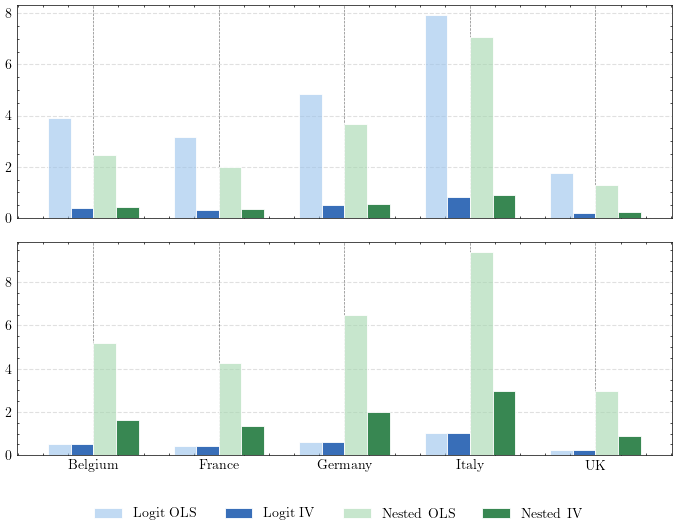

In [13]:
order = ['Logit OLS', 'Logit IV', 'Nested OLS', 'Nested IV']

price = country['Price change (%)'].unstack()[order].reindex(countries.values())
div = (pd.DataFrame(diversion)
       .groupby(['country', 'Model'])['Partner diversion (%)']
       .mean()
       .unstack()[order]
       .reindex(countries.values()))

colors = [
    (0.60, 0.76, 0.92, 0.60),  # Logit OLS: light pastel blue
    (0.22, 0.43, 0.72, 1.00),  # Logit IV: dark blue
    (0.64, 0.84, 0.68, 0.60),  # Nested OLS: light pastel green
    (0.22, 0.53, 0.32, 1.00),  # Nested IV: dark green
]

fig, axes = plt.subplots(2, 1, figsize=(7, 5.5), sharex=True)

for ax, df, ylabel in zip(
    axes,
    [price, div],
    ['% Price increase', '% Partner diversion']
):
    df.plot.bar(
        ax=ax,
        width=0.72,
        rot=0,
        legend=False,
        color=colors,
        edgecolor='white',
        linewidth=0.6
    )

    ax.set_ylabel(ylabel, fontweight='bold')
    ax.set_xlabel('')
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.12, linewidth=0.8)

    # keep full default square border, just make text cleaner
    ax.tick_params(axis='both', length=0, labelsize=10)

    for label in ax.get_xticklabels():
        label.set_fontweight('bold')
    for label in ax.get_yticklabels():
        label.set_fontweight('bold')

axes[1].tick_params(axis='x', labelbottom=True)

handles, labels = axes[0].get_legend_handles_labels()
legend = fig.legend(
    handles, labels,
    loc='lower center',
    ncol=4,
    frameon=False,
    bbox_to_anchor=(0.5, 0.01),
    prop={'weight': 'bold', 'size': 10}
)

fig.tight_layout(rect=[0, 0.09, 1, 1])

fig.savefig(OUT / 'comparison_countries.pdf', bbox_inches='tight')
fig.savefig(OUT / 'comparison_countries.png', dpi=300, bbox_inches='tight')
plt.show()

# Robustness checks
Re-estimate both IV regressions after adding a third COUNT instrument:
rival cars in other classes. Market-size changes re-estimate all four models and their costs.
A failed cost check is recorded explicitly, without clipping or dropping
individual markets from a reported average.

In [6]:
extra = other_class_count/other_class_count.std(ddof=0)
alt_fits = fit_models(data,np.column_stack([Z,extra]))
alt_models = {name:pricing_model(data,fit) for name,fit in alt_fits.items() if name.endswith('IV')}
alt_mergers,_,_ = counterfactual(data,alt_models)
alt_mergers.to_csv(OUT/'instrument_robustness_markets.csv',index=False)
alt_summary = alt_mergers.groupby('Model').mean(numeric_only=True)
alt_summary['alpha'] = pd.Series({n:f.params.neg_log_price for n,f in alt_fits.items()})
alt_summary['rho'] = pd.Series({n:f.params.get('log_within',0.) for n,f in alt_fits.items()})
display(alt_summary[['alpha','rho','Price change (%)']].round(4));alt_summary.to_csv(OUT/'instrument_robustness.csv')

robustness=[]
for h in [2.,3.]:
    d=data_for(h)
    ff=fit_models(d)
    for name,fit in ff.items():
        r=pricing_model(d,fit);cost=r.compute_costs().ravel()
        if (cost<=0).any():
            robustness.append({'Market size':h,'Model':name,'Status':'Failed cost check',
                               'Nonpositive costs':int((cost<=0).sum())})
            continue
        mm,_,_=counterfactual(d,{name:r})
        assert len(mm)==150
        mm.to_csv(OUT/f'markets_h{h}_{name.replace(" ","_")}.csv',index=False)
        row=mm.mean(numeric_only=True).to_dict()
        row.update({'Market size':h,'Model':name,'Status':'150 markets solved',
                    'alpha':fit.params.neg_log_price,'rho':fit.params.get('log_within',0.),'Nonpositive costs':0})
        robustness.append(row)
pd.DataFrame(robustness).to_csv(OUT/'market_size_robustness.csv',index=False)
display(pd.DataFrame(robustness)[['Market size','Model','Status','Price change (%)']].round(4))

Solved all markets: Logit IV
Solved all markets: Nested IV


,alpha,rho,Price change (%)
Model,,,
Logit IV,2.6100,0.0000,0.3884
Nested IV,4.7538,0.2185,0.4813


Solved all markets: Logit OLS
Solved all markets: Logit IV
Solved all markets: Nested OLS
Solved all markets: Nested IV
Solved all markets: Logit IV
Solved all markets: Nested OLS
Solved all markets: Nested IV


,Market size,Model,Status,Price change (%)
0,2.0,Logit OLS,150 markets solved,3.5594
1,2.0,Logit IV,150 markets solved,0.3578
2,2.0,Nested OLS,150 markets solved,3.2968
3,2.0,Nested IV,150 markets solved,0.4747
4,3.0,Logit OLS,Failed cost check,NaN
5,3.0,Logit IV,150 markets solved,0.5408
6,3.0,Nested OLS,150 markets solved,3.3131
7,3.0,Nested IV,150 markets solved,0.5354


# Fixed-effect sensitivity and the theory test
Additive year effects are a sensitivity check, not imposed to obtain a
desired coefficient. The theory test retains market effects and tests
characteristics and brand effects jointly in a linear share regression.

In [7]:
fe_rows=[]
for effects in [('ma','brd'),('ma','brd','ye'),('market_ids','brd')]:
    for name,fit in fit_models(data,effects=effects).items():
        fe_rows.append({'Effects':'+'.join(effects),'Model':name,
            'alpha':fit.params.neg_log_price,'rho':fit.params.get('log_within',0.)})
pd.DataFrame(fe_rows).to_csv(OUT/'fixed_effect_sensitivity.csv',index=False)
display(pd.DataFrame(fe_rows))
X=data[['neg_log_price']+controls].join(pd.get_dummies(
    data[['market_ids','brd']].astype(str),drop_first=True,dtype=float))
theory_fit=sm.OLS(data.delta,sm.add_constant(X)).fit(
    cov_type='cluster',cov_kwds={'groups':data.co,'use_correction':False})
terms=[c for c in X if c in controls or c.startswith('brd_')]
R=np.eye(len(theory_fit.params))[[theory_fit.params.index.get_loc(c) for c in terms]]
test=theory_fit.f_test(R)
theory=pd.DataFrame({'F':[float(test.fvalue)],'df_num':[int(test.df_num)],
                    'df_denom':[int(test.df_denom)],'p':[float(test.pvalue)]})
display(theory);theory.to_csv(OUT/'theory_test.csv',index=False)

,Effects,Model,alpha,rho
0,ma+brd,Logit OLS,1.14537,0.00000
1,ma+brd,Logit IV,2.39288,0.00000
2,ma+brd,Nested OLS,1.16288,0.65768
3,ma+brd,Nested IV,4.11438,0.16794
4,ma+brd+ye,Logit OLS,0.67590,0.00000
5,ma+brd+ye,Logit IV,5.78073,0.00000
6,ma+brd+ye,Nested OLS,0.76376,0.65360
7,ma+brd+ye,Nested IV,7.08815,0.03680
8,market_ids+brd,Logit OLS,0.48866,0.00000
9,market_ids+brd,Logit IV,5.22870,0.00000


,F,df_num,df_denom,p
0,53.00507,39,284,3.34727e-108
